<a href="https://colab.research.google.com/github/OthmaneL4/IA-y-Big-Data-/blob/main/Copia_de_S6_1_Mas_sobre_n%C3%BAcleo_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Sesión 6.1: Más sobre el núcleo de Python (parte 1)

* S6.1. Funciones
* S6.2. Parámetros arbitrarios: `*args` y `**kwargs`
* S6.3. Argumentos *sólo por nombre*
* S6.4. Espacios de nombre y paso por asignación
* S6.5. Funciones **lambda**
* S6.6. Generadores
* S6.7. Manejo de excepciones
* S6.8. Lectura y escritura de archivos

# S6.1 Funciones


Hasta ahora hemos definido código en una celda: declaramos parámetros en variables, luego hacemos alguna operación e imprimimos y/o devolvemos un resultado.

Para generalizar esto podemos declarar **funciones**, de manera de que no sea necesario redefinir variables en el código para calcular/realizar nuestra operación con diferentes parámetros. En Python las funciones se definen con la sentencia `def` y con `return` se devuelve un valor

In [1]:
def cuadrado(numero):
    """Dado un escalar, devuelve su potencia cuadrada"""
    resulta = numero**2
    return resulta

In [2]:
cuadrado(3)

9

In [ ]:
cuadrado(2e10)

In [ ]:
cuadrado(5-1j)

In [ ]:
cuadrado(3 + 2)

Notar que no **exigimos un tipo de dato** en la signatura. Python es dinámico: se esperan **comportamientos** en vez de tipos. Un tipo de datos puede implementar distintos comportamientos y *"funcionar"*

Si un número, cualquiera sea su tipo, puede elevarse al cuadrado, ¿por qué deberíamos hacer una función equivalente para enteros, otra para flotantes de simple precisión y otra para complejos como se hace en otros lenguajes?

Esto es lo que se conoce como **[Duck typing](https://es.wikipedia.org/wiki/Duck_typing)**, que es el estilo de orientación a objetos que utiliza Python.

   *"Cuando veo un ave que camina como un pato, nada como un pato y suena como un pato, a esa ave yo le digo pato."*



In [3]:
cuadrado("hola mundo")

TypeError: unsupported operand type(s) for ** or pow(): 'str' and 'int'

Obviamente, si el objeto (el tipo del objeto) que pasamos no soporta el comportamiento que esperamos (en este caso no se puede "elevar al cuadrado" una cadena) fallará.

Pero es mejor que nos avise del error, ¿no? ¿Por qué querríamos elevar una cadena al cuadrado? ¿qué significado tendría?


![](http://img.desmotivaciones.es/201109/CliffRobertsonSpiderman1.jpg)




#### Parámetros y más parámetros

La definición de funciones es muy flexible. No exige ni siquiera pasar parámetros o devolver resultados


In [4]:
# definimos una función que no recibe ni devuelve parámetros pero hace algo.
def hola():
    """
    una función que saluda
    de una manera muy amable

    """
    print("¡Hola curso!")
    return "de nuevo"

print(hola())   # llamamos a esa función

¡Hola curso!
de nuevo


In [5]:
print(hola())

¡Hola curso!
de nuevo


Si la función no tiene un `return`, lo que devuelve es `None`.

In [ ]:
saludo = hola()
print(saludo)

¡Hola curso!
de nuevo


In [ ]:
print(hola.__doc__)


una función que saluda
de una manera muy amable




### Un paréntesis: docstrings

Módulos, funciones, métodos y clases pueden tener una "cadena de documentación", que se define como un string
en la primera linea del cuerpo. Python automáticamente asigna esa cadena al atributo `__doc__` del objeto en cuestión.

Los `docstrings` **son opcionales pero muy recomendados**, porque a diferencia de los comentarios (que se ponen con `#`), son los que se muestran en la ayuda interactiva y tambien pueden post-procesarse para generar documentación de referencia automática



In [ ]:
hola.__doc__ = 'hola'


Tip: `__doc__` es un atributo que se puede escribir, por lo tanto podríamos asignarle un texto construído dinámicamente

#### Múltiples puntos de salida

También puede haber múltiples `return` en una función. El primero en ejecutarse determinará el valor que la función devuelve

In [7]:
def saludo(coloquial,nombre='Vicente'):
    if coloquial:
        VAL = "Hola %s!"%nombre
        return VAL
    else:
        return "Buenas tardes, %s"%nombre

    # Esto tambien podria ser una linea con la estructura ternaria
    # return "Hola chochamus!" if coloquial else  "Buenas tardes, señores"


saludo(False)

'Buenas tardes, Vicente'

In [8]:
saludo(coloquial=False)

'Buenas tardes, Vicente'

### Parámetros opcionales

Se pueden definir parámetros opcionales, que **toman un valor *default* ** cuando no se los explicíta

La función `saluda` recibe un parámetro requerido `nombre` (es requerido porque no tiene valor por omisión)  y dos parámetros opcionales (`saludo` y `sufijo`).

- Si sólo paso 1 parámetro será `nombre` y los valores default se usarán para los otros parámetros
- Si paso 2 se usaran para `nombre` y `saludo` mientras que `sufijo` usará el default
- Si paso todos los parámetros no se usaran los valores por omisión.


In [ ]:
def saludar(nombre, saludo="Hola", sufijo="¿qué tal?"):
    """Dado un nombre y, opcionalmente, un saludo y/o sufijo, devuelve
    una cadena saludo + nombre + sufijo"""

    return "{} {}, {}".format(saludo, nombre, sufijo)

print(saludar("Martín"))
print(saludar("Fernando", 'Ey'))
print(saludar("Rodrigo Mendoza", "Estimado", 'usted es un genio'))

In [ ]:
saludar('oscar')

Pero ¿qué pasa si quiero usar el default para `saludo` pero no para `sufijo`?

Podemos pasar los **parámetros por nombre**

In [ ]:
saludar('Lionel', sufijo="que golazo hiciste")    # saludo no se explicitó, se usa el default ("Hola")

Entre los parámetros por nombre no importa el órden, pero si mezclamos las dos formas, los **parámetros por posición, deben ir antes** de los parámetros por nombre.

## Ejercicios S6.1. Funciones

####S6.1.1. Ecuación de segundo grado

Definir una función para encontrar las raíces en el plano real en la ecuación de segundo grado   $$x_{1,2} = \frac{-b \pm \sqrt {b^2-4ac}}{2a}$$ El parámetro `a` es obligatorio, y `b` y `c` son opcionales con default 0. Devuelve una tupla con ambas raices. Luego mejore la implemtación para encontrar también las raices en el plano complejo cuando sea necesario.

In [9]:
import cmath
# Utilizamos esta libreria porque nos permite trabajar
# con raizes cuadradas tranto positivas como negativos.
def ecuacion_segundo_grado(a, b = 0, c = 0):
  # comprobamos que a no es 0
  if a == 0:
    print("El coeficiente 'a' no puede ser cero.")
    return
  discriminante = b**2 - 4*a*c

  x1 = (-b + cmath.sqrt(discriminante)) / (2*a)
  x2 = (-b - cmath.sqrt(discriminante)) / (2*a)

  return (x1, x2)



In [10]:
ecuacion_segundo_grado(1,-5,6)

(3.0, 2.0)

#### S6.1.2. Marquesina

Definir una función `marquesina` que, dado un objeto, la devuelve como un texto decorado en una caja. El, ancho, alto del relleno y el caracter de decoración son parámetros opcionales. Por ejemplo, dada `"Hola"`, devuelve

```
     *****************
     *      Hola     *
     *****************
```

In [23]:
#### def marquesina(cadena, ancho=60, alto=1, caracter="*"):

def marquesina(objeto, ancho=15, alto=0, caracter="*"):
  texto = str(objeto)
  ancho = max(ancho, len(texto))
  borde = caracter * (ancho +2)

  print(borde)

  for i in range(alto):
    print(caracter + " " * ancho + caracter)

  print(caracter + texto.center(ancho) + caracter)

  for i in range(alto):
    print(caracter + " " * ancho + caracter)

  print(borde)




In [25]:
marquesina("Hola")


*****************
*      Hola     *
*****************


<!--

 https://gist.githubusercontent.com/mgaitan/cb0ad9778453607acb49/raw/8d85d2184a4b46b48440cf5b5d95062801a08cce/baskara.py

https://gist.githubusercontent.com/mgaitan/6319640/raw/8183dc5b214397f0ff2d38a25ebdd128a1a3ca0f/gistfile1.txt
//-->

# S6.2. Parámetros arbitrarios: `*args` y `**kwargs`

Hasta aqui todo bonito. Pero ¿qué tal si quiero definir una función que acepte una cantidad arbitraria de parámetros? Aquí aparecen `*args` y `**kwargs`. Por ejemplo la función `zip` recibe una cantidad arbitraria de iteradores y devuelve tuplas con los i-elementos de cada una

In [26]:
list(zip((1, 2, 3), ('a', 'b', 'c'), ('alfa', 'beta', 'gama', 'theta'),  ('alfa', 'beta', 'gama', 'theta'),  ('alfa', 'beta', 'gama', 'theta')))

[(1, 'a', 'alfa', 'alfa', 'alfa'),
 (2, 'b', 'beta', 'beta', 'beta'),
 (3, 'c', 'gama', 'gama', 'gama')]

Entonces ¿cómo definiríamos una función al estilo  `zip` que recibe cuantos argumentos queramos?

In [27]:
def prod(*args):
  """
  calcula el producto de todos los argumentos dados
  """
  print(args)        # args es una tupla de los argumentos posicionales dados.
  producto = 1
  for num in args:
    producto *= num     # producto = producto * num

  return producto

In [28]:
#print(list(range(16)))
#print(tuple(range(16)))

prod(4,3,2,5,7,8,10,25)

(4, 3, 2, 5, 7, 8, 10, 25)


1680000

In [29]:
prod(10, 20, 2.1)

(10, 20, 2.1)


420.0

Por otro lado, tenemos como ejemplo el constructor `dict` que acepta una argumentos arbitrarios por clave para crear un diccionario

In [30]:
dict(Carlitos=10, Gaitán='Jugador Nº 12', Gonzales= 'no juega',Saul='Crack')

{'Carlitos': 10,
 'Gaitán': 'Jugador Nº 12',
 'Gonzales': 'no juega',
 'Saul': 'Crack'}

¿Cómo definir una función que permita esa flexibilidad? Eso se hace con `**kwarg`

In [31]:
def itemizar(**kwargs):
    """
    genera una lista de items con todos los argumentos dados
    """
    print(kwargs.items())
    for clave, valor in kwargs.items():
        print('* {0} ({1})'.format(clave, valor))

In [32]:
itemizar(tornillos=10, lija=2, cualquiera=10, cosa=40)

dict_items([('tornillos', 10), ('lija', 2), ('cualquiera', 10), ('cosa', 40)])
* tornillos (10)
* lija (2)
* cualquiera (10)
* cosa (40)


En resumen, con `*args` se indica *"mapear todos los argumentos posicionales no explícitos a una tupla llamada `args`"*. Y con `**kwargs` se indica "mapear todos los argumentos de palabra clave no explícitos a un diccionario llamado `kwargs`".

In [33]:
def f(a1,*args,**kwargs):
    print('a1=', a1)
    print('args=', args)
    print('kwargs=', kwargs)


In [34]:
f(4)   # solo definido el parámetro común a

a1= 4
args= ()
kwargs= {}


In [35]:
f('valor', 1, 2)    # 'a1' y dos argumentos posicionales arbitrarios

a1= valor
args= (1, 2)
kwargs= {}


In [36]:
f('2', 1, 2, color='azul', detallado=True)   #

a1= 2
args= (1, 2)
kwargs= {'color': 'azul', 'detallado': True}


**NOTA**: No es necesario los nombres "args" y "kwargs", podemos llamarlas diferente, pero es una convención muy extendida. Estrictamente, los simbolos que indican cantidades arbitrarias de parametros son `*` y `**`. Además es posible poner parametros "comunes" antes de los parametros arbritarios.</div>






### La inversa: Desempaquetar secuencias o diccionarios directamente como argumentos

Si ya tengo los parámetros que quiero pasar a una función, los "desempaqueto".


In [37]:
otra_data = ('hola', '¿cómo va?')

saludo, sufijo = otra_data

saludar('José', saludo, sufijo)   # el primer elemento desempacado, va al primer arg posicional disponible...



NameError: name 'saludar' is not defined

In [ ]:
saludar('José', *otra_data)

In [ ]:
saludar??

In [ ]:
mi_data = {'nombre': 'Cristian', 'saludo': 'Ey', 'sufijo': 'qué onda?'}

saludar(**mi_data)

In [ ]:
def saludar2(nombre, saludo="Hola", sufijo="¿qué tal?", **kwargs):
    """Dado un nombre y, opcionalmente, un saludo y/o sufijo, devuelve
    una cadena saludo + nombre + sufijo"""

    return "{saludo} {nombre}, {sufijo}".format(**locals())  #la funcion locals() devuelve el diccionario de todos los objetos definidos en el espacio de nombres



In [ ]:
saludar2(**mi_data)


Obviamente, si pasamos más parámetros de los esperados por la función (y no permite parámetros arbritrarios), dará un error

In [ ]:
mi_data = {'nombre': 'Cristian', 'saludo': 'Ey', 'sufijo': 'qué onda', 'color': 'roja'}
saludar(**mi_data)

## Ejercicios S6.2. Parámetros arbitrarios:

#### S6.2.1. Dada las funciones `prod` y `marquesina` definidas con anterioridad, redefine `prod` agregando un parámetro opcional `enmamarcar` (`False` por defecto) que si es verdadero devuelve el resultado del producto en una marquesina. Cualquier otro parámetro se pasa directamente a la función marquesina.



In [38]:
#def prod(*args, enmarcar=False, **kwargs):

def prod(*args, enmamarcar =False , **kwargs):
  resultado = 1

  for numero in args:
    resultado *= numero

  if enmamarcar:
    return marquesina(resultado, **kwargs)

  return resultado



#Ejemplo: print(prod(2,3,enmarcar=True))

In [39]:
print(prod(2,3,enmarcar=True))

6


# S6.3. Argumentos *solo por nombre*

La posibilidad de pasar una cantidad arbitraria de argumentos, sea por posición o por nombre, es una ventaja que vuelve a Python muy poderoso.

Una limitación que existía en Python 2 era que no se podían definir argumentos por nombre luego de un `*args`



In [40]:
%%python2.7
# ese magic ^ ejecuta esta celda con python2
def f(*args, mayus=False):
    s = ' '.join(args)
    return s.upper() if mayus else s

f('hola', 'curso1', mayus=True)

UsageError: Cell magic `%%python2.7` not found.


In [41]:
def f(*args, mayus=False):
    s = ' '.join(args)
    return s.upper() if mayus else s

f('hola', 'curso!', mayus=True)

'HOLA CURSO!'

Obviamente, en ese caso la única forma de "setear" la opción `mayus` es **explícitamente a través del nombre**, porque de otra manera el argumento sería capturado por la tupla de argumentos posicionales `*args`.

Más aun, Python 3 también permite este tipo de **argumentos sólo por nombre** sin estar precedidos por argumentos variables y muchas veces son muy útiles.



In [ ]:
def marquesina(cadena, ancho=60, alto=1, caracter="*"):
    cadena = str(cadena).center(ancho)
    cadena = caracter + cadena[1:-1] + caracter
    cadena += '\n'
    relleno = " " * ancho
    relleno = caracter + relleno[1:-1] + caracter
    relleno += '\n'
    tapa = caracter * ancho
    return tapa + '\n' + relleno * alto + cadena + relleno * alto + tapa

def sumar(a, b, enmarcar=False):
    result = a + b
    #print(enmarcar)
    if enmarcar:
        return marquesina(result)
    return result

print(sumar(1, 2))


In [ ]:
print(sumar(1, 2, 3))  # bug , cuidado!

Se soluciona con un asterístico para avisar que **comienzan argumentos asignables solo por nombre**

In [ ]:
def sumar(a, b, *, enmarcar=False):
    result = a + b
    if enmarcar:
        return marquesina(result)
    return result

sumar(1,2,3)

In [ ]:
print(sumar(1,2, enmarcar=True))

Después de todo, explícito es mejor que implícito, ente otras cosas

In [ ]:
%%python3
import this

# S6.4.  Espacios de nombre y paso por asignación

Una función define un **espacio de nombre** (namespace), es decir, un contexto donde un nombre de variable refiere a un objeto unívoco dentro de ese espacio. Si un nombre no existe en el espacio de nombre local, se busca en el espacio global (módulo o sesión)


In [42]:
pi = 3.14

def area(r):
    return pi * r * r       # pi no está en en el espacio local, se usa el definido fuera de la función

r1 =1
area(r1)

3.14

In [ ]:
pi = 3.14

def area2(r,pi=12):
    return pi * r * r      # en este caso, se usa el pi pasado a la función

print(area2(1))
print(pi)                      # pero afuera sigue valiendo el del espacio global

**TIP**: dentro de cualquier namespace, la función `locals()` devuelve el diccionario de nombres definidos

In [ ]:
pi = 2
def namespaces(a, b):
    BLAH = 'bleh'
    print(locals())
#print(locals())
namespaces('1', b='algo')

En python se dice que los argumentos se pasan "por asignación", es decir, se asigna un nombre en el espacio de nombres local a un objeto existente, independientemente de si ya tiene un nombre en el espacio global.  Pero si ese objeto es mutable, la función podría modificar el objeto


In [ ]:
def f2(l):
    l[0] = 10
    return l


lista = ['a', 'b']
print(f2(lista))

In [ ]:
def f3(l):
    l1 = l.copy()
    l1[0] = 10
    return l1


lista = ['a', 'b']
print(f3(lista))
lista

En general, siempre es mejor que la funciones devuelvan objetos nuevos

In [ ]:
def f2(l):
    return [10] + l[1:]

lista = ['a', 'b']
print(f2(lista))
lista


## Ejercicios S6.4. Espacios de nombre y paso por asignación

#### S6.4.1 Una función puede retornar cualquier objeto y en Python todo es un objeto. Define una [función de orden superior](https://es.wikipedia.org/wiki/Funci%C3%B3n_de_orden_superior) (función que devuelve funciones) llamada `lineal` que dados los coeficientes `a` y `b` devuelve $$f(x) = ax + b$$

In [43]:
#def lineal(a,b):
#   def f(x):
#      ....
#      return ...
#   return f

def lineal(a,b):
  def f(x):
    return a*x + b
  return f

#Ejemplo:
#mifuncion=lineal(2,4)
#print(mifuncion(3))

In [44]:
# Creamos una función con a = 2 y b = 3
f = lineal(2, 3)

# Comprobamos los resultados
print(f(5))
print(f(10))
print(f(20))

13
23
43


# S6.5. Funciones lambda

Una función lambda es una pequeña **función anónima**, la cual puede tomar cualquier número de argumentos, pero solo puede tener una expresión.

### Sintaxis:
```python
lambda argumentos: expresión
```

### Uso común:
Se utilizan frecuentemente con funciones como `map()`, `filter()`, y `sorted()`.


Ejemplos:

In [45]:
x = lambda a : a + 10
print(x(5))

y = lambda a, b : a * b
print(y(5, 6))

z = lambda a, b, c : a + b + c
print(z(5, 6, 2))

15
30
13


Resulta complicado explicar las diferencias, y para que te hagas una idea de ello te dejo con la siguiente cita sacada de la documentación oficial.

> “*Python lambdas are only a shorthand notation if you’re too lazy to define a function.*”

Lo que significa algo así como, “las funciones lambda son simplemente una versión acortada, que puedes usar si te da pereza escribir una función”

Lo que sería una función que suma dos números como la siguiente.

```Python
def suma(a, b):
    return a+b
```

Se podría expresar en forma de una función lambda de la siguiente manera.


```Python
lambda a, b : a + b
```

La primera diferencia es que **una función lambda no tiene un nombre**, y por lo tanto salvo que sea asignada a una variable, es totalmente inútil. Para ello debemos.

```Python
suma = lambda a, b: a + b
```
Una vez tenemos la función, es posible llamarla como si de una función normal se tratase.

```Python
suma(2, 4)
```

In [46]:
# Ejemplo guiado 1: Función lambda básica
# Función tradicional
def cuadrado(x):
  return x**2

# Función lambda equivalente
cuadrado_lambda = lambda x : x**2

print("Función tradicional:", cuadrado(5))
print("Función lambda:", cuadrado_lambda(5))

Función tradicional: 25
Función lambda: 25


In [ ]:
# Ejemplo guiado 2: Usando lambda con map()
numeros = [1, 2, 3, 4, 5]

# Aplicar una función a todos los elementos
# Usando una función lambda, crea una nueva lista con los cuadrados
# cada uno de los números de dicha lista
# Usa las funciones list(*args, **kwargs) y map(func, iterable) y
cuadrados = map(lambda x: x**2,numeros)
for cuadrado in cuadrados:
  print(cuadrado)

# Convertir temperaturas de Celsius a Fahrenheit
celsius = [0, 20, 30, 40]
fahrenheit = list(map(lambda c : (c * 9/5)+32, celsius))
#print(fahrenheit(40))
print("Celsius a Fahrenheit:", fahrenheit)

1
4
9
16
25
Celsius a Fahrenheit: [32.0, 68.0, 86.0, 104.0]


In [ ]:
# Ejemplo 3: Usando lambda con filter()
numeros = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

# Filtrar números pares
# Usa la función list y filter
pares = list(filter(lambda x: x % 2 == 0, numeros))
for par in pares:
  print(par)
print("Números pares:", pares)

# Filtrar números mayores que 5
mayores_5 = list(filter(lambda x: x>5 and x%2==0, numeros))
print("Mayores que 5:", mayores_5) #Mayores que 5: [6, 8, 10]

2
4
6
8
10
Números pares: [2, 4, 6, 8, 10]
Mayores que 5: [6, 8, 10]


In [ ]:
# Ejemplo 4: Usando lambda con sorted()
estudiantes = [('Ana', 85), ('Carlos', 90), ('Beatriz', 78), ('David', 92)]

# Ordenar por nombre (key 0)
# Usa la función sorted. En key usa una función lamdba x[0] nombre

por_nombre = sorted(estudiantes, key=lambda x: x[0], reverse=False)
print("Ordenado por nombre:", por_nombre)

# Ordenar por calificación (descendente) (key 1)
#por_calificacion=
#print("Ordenado por calificación:", por_calificacion)
#Ordenado por calificación: [('David', 92), ('Carlos', 90), ('Ana', 85), ('Beatriz', 78)]

# S6.6. Generadores

Los generadores son similares a las funciones, pero permiten crear **una serie de resultados** para ser iterados (o sea, genera un iterador), devolviendo un valor por cada llamada. Ejemplos de funciones generadoras son `zip`, `enumerate`, `range` y `reversed`, que ya vimos.

También mencionamos la versión por comprensión `(f(x) for x in iter)`. La forma funcional es casi igual a la las funciones comunes, pero en vez de `return` se utiliza `yield` que funciona como **una pausa** (devolviendo opcionalmente un valor) en la ejecución.


In [47]:
def generador_ejemplo():
    print('antes del primer yield')
    yield 1    # sale devolviendo. la proxima llamada comenzará en la siguiente linea
    print('antes del segundo')
    yield      # como return, puede devolver None
    print('antes del último')
    yield 10
    print('final')

In [48]:
valores = generador_ejemplo()
valores

<generator object generador_ejemplo at 0x7d6ee668dfc0>

Para pedirles los valores uno a uno a un iterador (un generador es siempre un iterador), podemos usar la función `next`

In [ ]:
next(valores)

antes del primer yield


1

In [ ]:
next(valores)

antes del segundo


In [ ]:
next(valores)

antes del último


10

In [ ]:
next(valores)

final


StopIteration: 

Que es básicamente lo que hace la sentencia `for`

In [ ]:
for valor in generador_ejemplo():
    print('Valor: ', valor)

La clave de un generador es que **no es necesario computar todos los valores posibles** de una serie, sino que los vamos creando uno a uno *bajo demanda*. Quizás antes de terminar la serie, podemos dar por concluido el cómputo, y entonces habremos ahorrado tiempo de procesador y memoria.

In [ ]:
def fibonacci(n):
    """Generador de n primeros numeros de fibonacci"""
    i = 0
    a, b = 0, 1
    while i < n:
        i += 1
        yield a            # devolvemos un valor. En la próxima llamada, devolverá desde este punto,
        a, b = b, a + b

list(fibonacci(20))

[0,
 1,
 1,
 2,
 3,
 5,
 8,
 13,
 21,
 34,
 55,
 89,
 144,
 233,
 377,
 610,
 987,
 1597,
 2584,
 4181]

#### Recursividad

Recurrencia, recursión o recursividad es la forma en la cual se especifica un proceso basado en su propia definición.  Es decir, traduciendolo al dominio de las funciones, en una recursividad una función se llama a si misma:

In [49]:
import time

def cuentaatras(n):
    time.sleep(1)
    if n==0:
        print("Despegue!\n")
    else:
        print("%d\n"%n)
        cuentaatras(n-1)

cuentaatras(5)

5

4

3

2

1

Despegue!



## Ejercicios S6.6. Generadores

#### S6.6.1. Define un generador `encadenar` que recibe una cantidad arbitraria de iteradores como parámetros y encadena el último elemento de un iterador con el primero del siguiente. Por ejemplo `list(encadenar('BA', 'DC'))` devuelve `['B', 'A', 'D', 'C']`.

In [50]:
#def encadenar(*args):
def encadenar (*args):
  for iterable in args:
    for elemento in iterable:
      yield elemento

#list(encadenar('AB', 'CD'))
#salida: ['B', 'A', 'D', 'C']

In [51]:
print(list(encadenar("BA", "DC")))
print(list(encadenar([1, 2, 3], [4, 5, 6])))

['B', 'A', 'D', 'C']
[1, 2, 3, 4, 5, 6]


#### S6.6.2.  La función de fibonacci se puede implementar como en el ejemplo anterior pero tambien usando recursividad, implementa la funcion de fibonacci utilizando recursividad:
<img src='https://drive.google.com/uc?id=1XhjvqQPUlE6itHeX_fMZj_owKP_YsChF' >

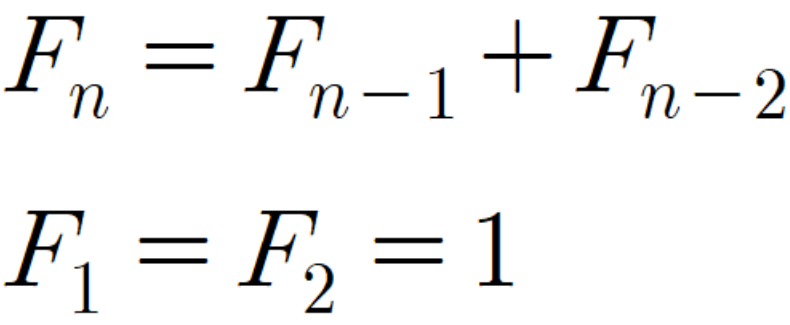

In [52]:
def fibonacci(n):

    if n == 1 or n == 2:
        return 1

    return fibonacci(n-1) + fibonacci(n-2)

# S6.7. Manejo de excepciones

Ya vimos que a veces suceden errores: por ejemplo, cuando apuntamos a un elemento mayor al tamaño de una secuencia, cuando pedimos el valor de una clave que no existe en un diccionario, cuando dividimos por cero, cuando intentamos un *casting de tipos* no válido, etc.

No hay problema interactivamente, porque podemos corregir y reintentar (lo que es genial), pero muchas veces queremos o necesitamos "capturar" el potencial error o excepción, ya sea para subsanarlo de alguna manera, registrarlo o lanzar otro más específico en reemplazo, etc.
   
La sintaxis es un poco parecida al `if / elif / else`

In [ ]:
int('diez')

In [ ]:
while True:
    try:
        x = int(input("Ingrese un número entero: "))
        print("qué lindo número el {}".format(x))
        break
    except ValueError:
        print("Eso no es un número válido.")

Una sintaxis más completa permite multiples bloques `except`, un mismo bloque except  un bloque `else` que se ejecuta cuando no se originó ninguna excepción y un bloque `finally` que se ejecuta siempre

In [ ]:

try:
    x = int(input("Ingrese el divisor: "))
    print(10/x)
except ZeroDivisionError:
    print("hubo un error de division por cero, obvio")
except ValueError:
    print("hubo un error de valor. Pon un numero! ")
else:
    print('todo salió bien. puedo hacer más operaciones')
finally:
    print('no sé qué pasó ni me interesa: yo me ejecuto igual')



¡Esto se usa mucho!  En la filosofía de Python, que espera comportamientos y no tipos,  es **mejor pedir perdón que pedir permiso**. Es decir, es preferible capturar potenciales errores de un intento de operación que verificar precondiciones.
   
## Ejercicios  S6.7. Manejo de excepciones

#### S6.7.1. Redefine el siguiente fragmento de código en una estructura `try / except`

```python
opciones = {'a': 'jugar', 'b': 'bailar', 'c': 'dormir siesta'}

opcion = input("Ingrese opcion ")
if opcion in opciones:
   print('Vamos a ', opciones[opcion])
else:
   print('Valor invalido')
```


In [ ]:
# Diccionario con las opciones disponibles
opciones = {'a': 'jugar', 'b': 'bailar', 'c': 'dormir siesta'}

# Solicitamos una opción al usuario
opcion = input("Ingrese opcion ")

# Intentamos acceder a la opción seleccionada
try:
    print('Vamos a ', opciones[opcion])

# Controlamos el error si la opción no existe
except KeyError:
    print('Valor invalido')

# S6.8. Lectura y escritura de archivos

Siempre necesitamos leer y escribir archivos. Es la forma básica de interactuar con el resto del sistema, introducir y exportar datos para la "computación". Como en Python todo es un objeto, lo que tenemos es un "objeto manejador de archivos" . La forma más básica de obtener uno es con la función `open()` que se le dice la ruta al archivo y modo/s, que se especifican con


       'r': lectura (default)
       'w': (sobre)escritura
       'a': agregar contenido al final
       'x': para escribir, pero no sobreescribe si existe el path
       'b': modo binario
       't': modo texto (default)
       '+': actualizar contenido
       



In [ ]:
%%writefile archivo.txt
UN EJEMPLO DE TEXTO

CON MULTIPLES LINEAS

SI!

In [ ]:
readme = open('archivo.txt')    # se usa modo default 'rt' (sólo lectura, formato texto)
print(readme)

Los objetos `file like` como `readme` tienen un método principal llamado `read` que lee `n` cantidad de caracteres (o bytes en modo binario) o todo el contenido del archivo si no se especifica

In [ ]:
texto = readme.read()
readme.close()
texto

In [ ]:
print(texto)

Atentos: el objeto manejador lleva internamente la **posición del cursor**. Por ejemplo, si invocan multiples veces el metodo `read()`, leerán porciones consecutivas del archivo.

Métodos útiles: `read()`, `readlines()`, `write()`, `writelines()`

A veces simplemente queremos hacer algo "linea por linea". En vez de usar `readlines()` y cargar todo en memoria (que puede ser grande), podemos iterar directamente sobre el archivo, que nos devolverá una línea

In [ ]:
readme = open('archivo.txt')
for linea in readme:
    print(linea[:-1].lower())

In [ ]:
readme = open('archivo.txt')
for i, linea in enumerate(readme):
    if i < 5:
        print(i,linea)
    else:
        break

In [ ]:
readme2 = open('archivo.txt', 'r')

print("".join(readme2.readlines()))


Hasta que no se invoca al método `close()` el archivo está manejado en memoria por Python (y puede causar conflictos si queremos abrir el archivo desde otro programa). Como los objetos `file` saben usar un bloque `with` (manejador de contexto), podemos usarlo para que se cierre automáticamente.

In [ ]:
with open('archivo.txt', 'r') as readme:
    lineas = readme.readlines()[0:5]    #mete las líneas en una lista
print(''.join(lineas))


## Ejercicios S6.8. Lectura y escritura de archivos

#### S6.8.1. Escriba una función que, dada la ruta de un archivo de texto, escriba otro archivo con igual nombre pero precedido por el prefijo `"upper_"` cuyo contenido es el del original, todo convertido a mayúsculas


In [56]:
import os

def convertidor(archivo):

    # Abrimos y leemos el archivo original
    with open(archivo, "r", encoding="utf-8") as fichero:
        contenido = fichero.read()

    # Convertimos el contenido a mayúsculas
    contenido = contenido.upper()

    # Obtenemos la carpeta y el nombre del archivo
    carpeta = os.path.dirname(archivo)
    nombre = os.path.basename(archivo)

    # Creamos el nombre del nuevo archivo
    nuevo_archivo = os.path.join(carpeta, "upper_" + nombre)

    # Creamos el archivo nuevo y escribimos el contenido
    with open(nuevo_archivo, "w", encoding="utf-8") as fichero:
        fichero.write(contenido)

    return nuevo_archivo


convertidor("archivo.txt")

'upper_archivo.txt'

In [54]:
with open("archivo.txt", "w", encoding="utf-8") as fichero:
    fichero.write("Hola, estoy aprendiendo Python.\n")
    fichero.write("Este es el ultimo ejercicio del cuaderno.")

In [55]:
convertidor("archivo.txt")

'upper_archivo.txt'

### Archivos binarios

La manipulación de archivos binarios es equivalente.

<img src='https://drive.google.com/uc?id=1OmKU4_J0W8HGoanZiBAIpKEguNpquzRx' >



In [ ]:
with open('img/circle.bmp', 'rb') as img_file:
    img_data = img_file.read()
img_data

In [ ]:
type(img_data)

Por ejemplo, podemos

In [ ]:
with open('img/circle_edited.bmp', 'wb') as img_file:
    img_file.write(img_data.replace(b'\xff', b'\x00'))

<img src='https://drive.google.com/uc?id=1zfFMAqahzJWOQe6Oc6Xnn-m0QBQ6hOF_' >

A veces, la información binaria es simplemente texto y sólo hace falta "decodificarlo" para que python lo convierta a un objeto unicode. Para eso se usa el método `decode()` al que se le pasa el tipo de "encoding" (latin-1, ascii, utf8, etc).

In [ ]:
img_data.decode('latin-1')[0:30]

esa representacion como texto de datos que no son texto no es muy util. Sin embargo a veces es util convertir a una representación hexadecimal

In [ ]:
img_data.hex()[0:30]

Qué pasa si una estructura de datos binaria del archivo es compuesta? Por ejemplo, texto, números, etc.  Para eso existe el módulo `struct`

In [ ]:
import struct

values = (1, 'ab'.encode('utf-8'), 2.7)
s = struct.Struct('I 2s f')
packed_data = s.pack(*values)

print('Original values:', values)
print('Format string  :', s.format)
print('Uses           :', s.size, 'bytes')
print('Packed Value   :', packed_data.hex())


In [ ]:
s.unpack(packed_data)

In [ ]:
savedatastruct = open('datastruct.txt', 'wb')
savedatastruct.write(packed_data)
savedatastruct.close()

In [ ]:
readdatastruct = open('datastruct.txt', 'rb')
savedpacked_data=readdatastruct.read()
readdatastruct.close()
print(savedpacked_data)
s.unpack(savedpacked_data)